# Choosing a better day at the park

A short walk can still lead to a long queue. I compare several ways to choose attractions while leaving enough time to reach the exit.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from parkroute.data import download, preprocess
from parkroute.environment import Park, Environment, Config, SCENARIOS
from parkroute.experiment import train, evaluate, paired_intervals, budget_experiment
from parkroute import plots
ROOT = Path.cwd()
if not (ROOT / 'parkroute').exists():
    raise RuntimeError('Open this notebook from the project folder.')
plots.style()


The next cell downloads a pinned public attraction table and checks its columns, identifiers, coordinates and numeric values. A matching local copy avoids another download. The source does not specify queue times, roads, opening hours or visitor preferences.

In [2]:
manifest = download(ROOT)
source, attractions, audit = preprocess(ROOT)
print(f"HTTP status: {manifest['status_code']}; downloaded bytes: {manifest['bytes']}")
print(f"Public records: {audit['rows']}; missing values: {audit['missing_values']}; duplicate IDs: {audit['duplicate_ids']}")
print('Source:', manifest['url'])
print('The duration field is treated as minutes for the environment; its unit is not declared in the CSV.')
selected = attractions[['poiName', 'duration', 'rating', 'n_reviews']].copy()
selected.index = np.arange(1, len(selected) + 1)
selected.index.name = 'Map label'
display(selected)


HTTP status: 200; downloaded bytes: 1713
Public records: 27; missing values: 0; duplicate IDs: 0
Source: https://raw.githubusercontent.com/junhua/SCAIR/ff457ed9c177c98dfe92ec5d8df608dfd8de0a8a/data/POI-MagicK.csv
The duration field is treated as minutes for the environment; its unit is not declared in the CSV.


,poiName,duration,rating,n_reviews
Map label,,,,
1,Space Mountain,10.0,4.6,1548
2,Buzz Lightyear's Space Ranger Spin,4.5,4.5,1449
3,Dumbo The Flying Elephant,1.5,4.4,163
4,The Many Adventures of Winnie the Pooh,4.0,4.4,326
5,It's A Small World,14.0,4.6,706
6,Haunted Mansion,10.0,4.5,372
7,Peter Pan's Flight,3.0,4.2,203
8,Big Thunder Mountain Railroad,7.0,4.7,1956
9,Pirates of the Caribbean,7.5,4.6,2547


The next figure places ten attractions on a local map. The roads connect nearby points and keep the graph connected. The other panels inspect the public ratings, review counts and visit-duration field.

Graph nodes: 13; undirected roads: 25


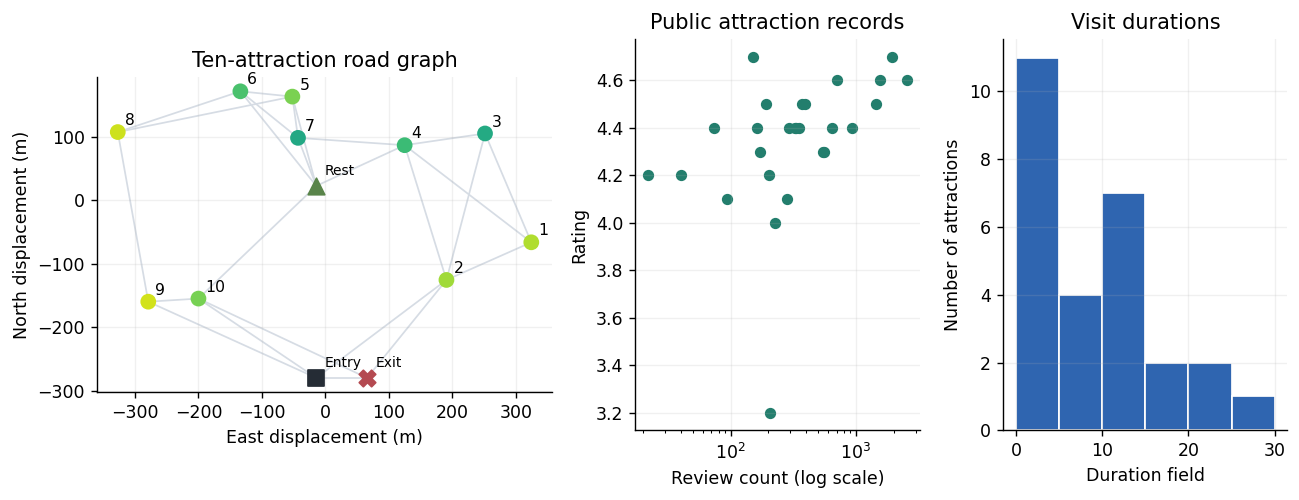

In [3]:
park = Park(attractions)
cfg = Config()
fig = plots.data_figure(source, park, ROOT)
plt.show()
print(f'Graph nodes: {park.size}; undirected roads: {len(park.edges)}')


The following cell shows the changing environment. Peak periods raise queues and walking costs. The disruption closes one road and increases queues at three attractions for 55 minutes. The shifted scenario starts earlier and has a larger queue increase.

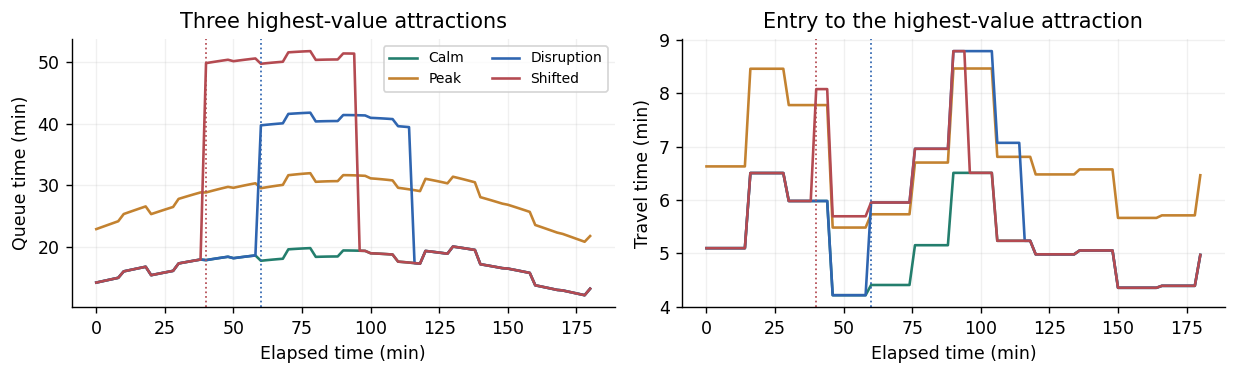

In [4]:
fig = plots.dynamics_figure(park, cfg, ROOT)
plt.show()


The next cell trains Q-learning and a small DQN with two hidden layers. The DQN uses NumPy, a replay buffer and a target network. Three independent training seeds expose variation between learned policies. Validation uses separate cases; the final models are evaluated later without further training.

Q-learning: training seed 11, 2500 episodes
DQN: training seed 11, 2500 episodes
Q-learning: training seed 22, 2500 episodes
DQN: training seed 22, 2500 episodes
Q-learning: training seed 33, 2500 episodes
DQN: training seed 33, 2500 episodes


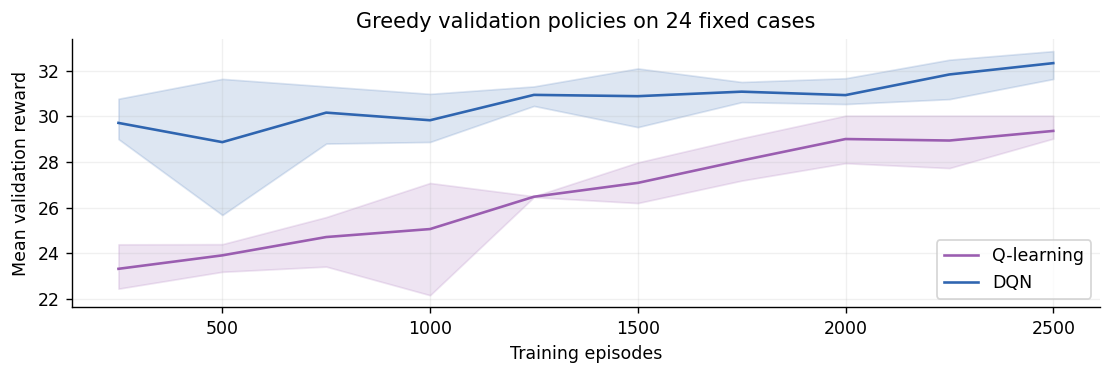

In [5]:
agents, training, checkpoints = train(park, cfg, ROOT)
fig = plots.learning_figure(checkpoints, ROOT)
plt.show()


The following cell compares policies on the same 80 cases per scenario. Coverage counts visited attractions. Preference satisfaction measures the fraction of the visitor's attraction value collected; it is a model score, not a survey response. The stale-input DQN keeps its queue and travel features at their initial values while retaining the common action mask.

,scenario,policy,reward,coverage,satisfaction,wait,walk,completion
0,calm,Adaptive greedy,38.08,51.62,54.40,75.25,33.94,95.00
1,calm,DQN,39.67,51.00,55.03,77.80,30.17,98.75
2,calm,DQN stale input,39.35,50.58,54.36,77.05,31.55,99.58
3,calm,Frozen route,35.51,51.50,50.80,78.43,28.18,97.50
4,calm,Nearest,35.65,52.12,51.43,78.90,27.83,96.25
5,calm,Q-learning,35.22,46.54,48.98,71.09,35.57,100.00
6,disruption,Adaptive greedy,37.10,49.75,51.24,72.43,35.45,100.00
7,disruption,DQN,38.09,49.83,53.45,76.15,33.86,98.33
8,disruption,DQN stale input,37.58,49.12,52.86,74.98,35.97,98.33
9,disruption,Frozen route,33.50,48.88,48.25,75.55,30.91,97.50


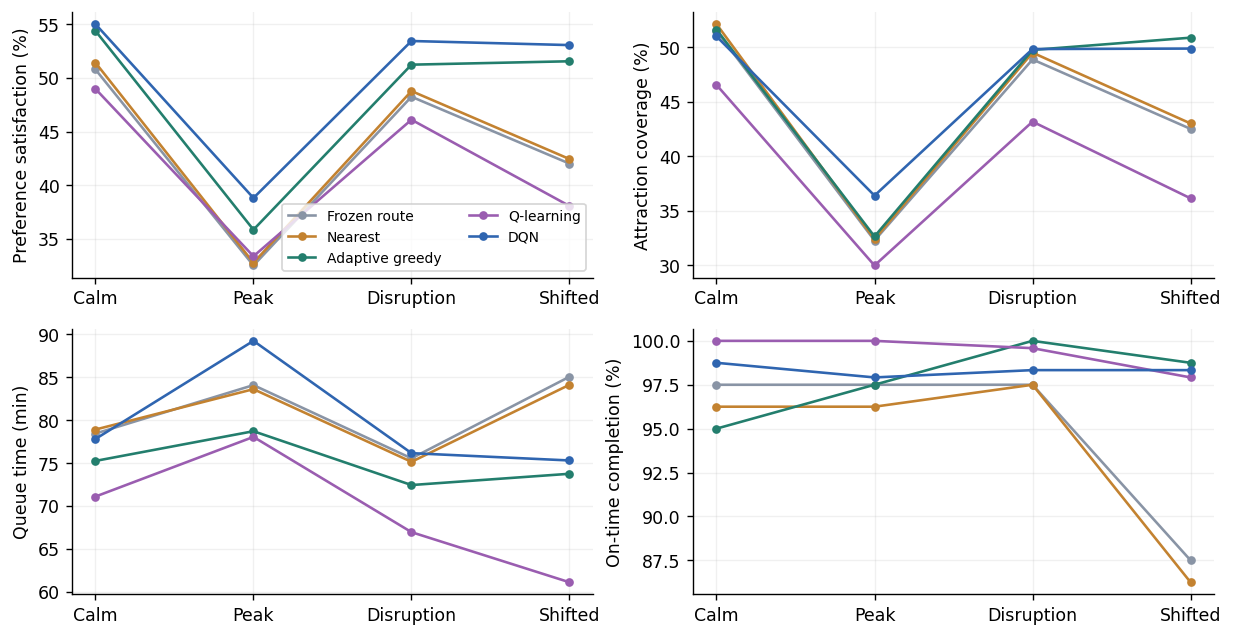

In [6]:
evaluation, summary = evaluate(park, cfg, agents, ROOT)
display(summary[['scenario', 'policy', 'reward', 'coverage', 'satisfaction', 'wait', 'walk', 'completion']].round(2))
fig = plots.performance_figure(evaluation, ROOT)
plt.show()


The next plot compares DQN reward with three alternatives. The intervals resample paired test cases after averaging each learned policy across training seeds. They describe variation across cases, rather than uncertainty over all possible training runs.

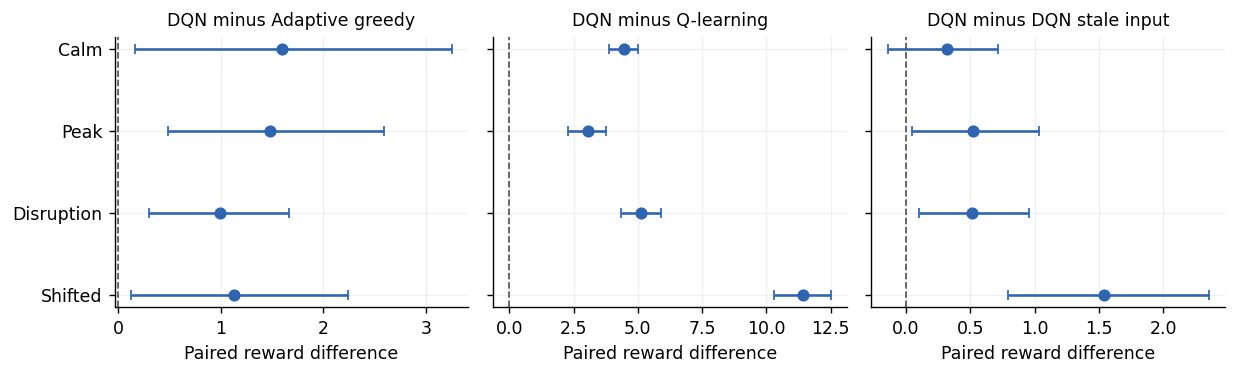

In [7]:
paired = paired_intervals(evaluation, ROOT)
fig = plots.paired_figure(paired, ROOT)
plt.show()


The following cell changes the time budget without retraining. These additional disruption cases test how the learned decisions behave with shorter and longer visits.

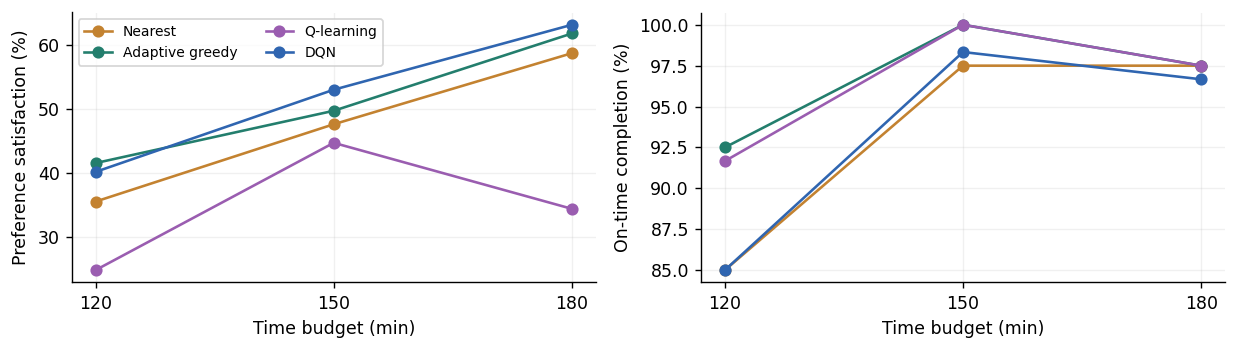

In [8]:
budgets = budget_experiment(park, cfg, agents, ROOT)
fig = plots.budget_figure(budgets, ROOT)
plt.show()


The final figure follows one fixed disruption case. The dashed red road marks the edge affected by the closure. The time bars show how walking, queueing and attraction visits consume the budget.

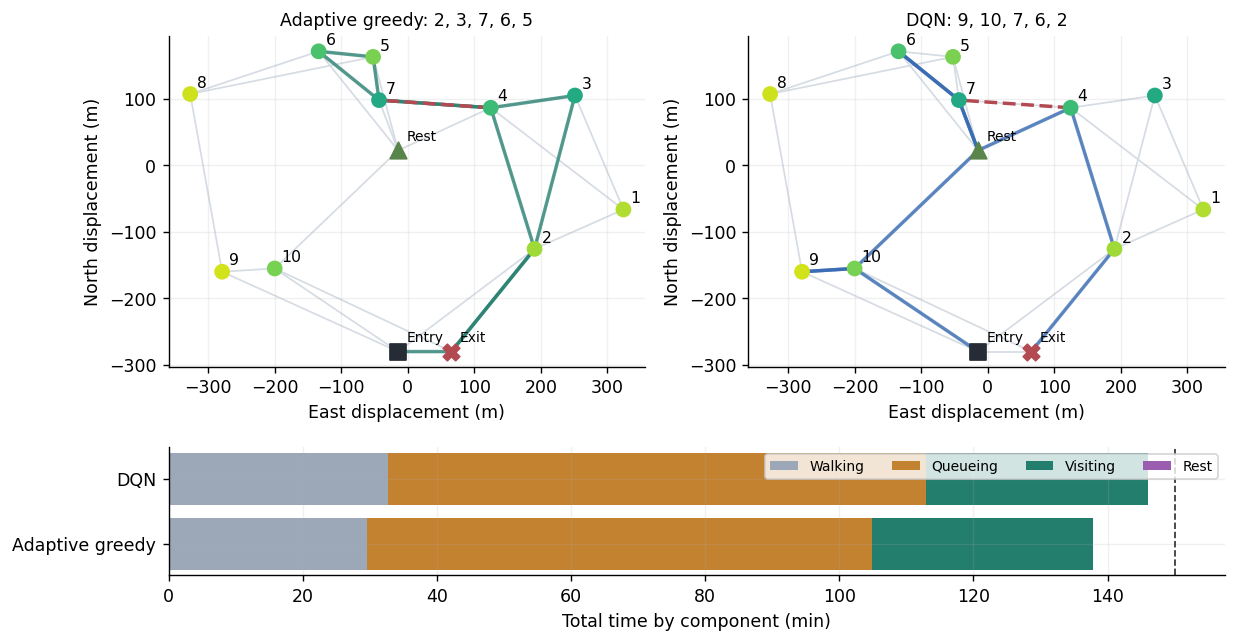

,policy,visits,satisfaction,wait,walk,time,completion
0,Adaptive greedy,5,52.20,75.22,29.61,137.83,100.0
1,DQN,5,55.32,80.30,32.66,145.95,100.0


In [9]:
fig, example = plots.route_figure(park, cfg, agents, ROOT)
plt.show()
display(example[['policy', 'visits', 'satisfaction', 'wait', 'walk', 'time', 'completion']].round(2))
